## Сравнение моделей

In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))

In [ ]:
from sklearn.pipeline import Pipeline
import pandas as pd
from src.transformers import DataCleaner, NaNCatboostImputer, FeatureCreator, MetaDataframeCreator, SimpleErrorDeleter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, make_scorer, recall_score, precision_score, accuracy_score, roc_auc_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from src.utils import show_metrics, show_weights
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import json
from pathlib import Path
import optuna
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
import numpy as np
from sklearn.base import clone
from statsmodels.stats.contingency_tables import mcnemar
import joblib

In [3]:
df = pd.read_csv('../data/raw/train.csv')
X = df.drop('Credit Default', axis=1)
y = df['Credit Default']

## Пайплайн препроцессинга

In [4]:
ohe_step = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                drop="first",
                sparse_output=False,
                handle_unknown="ignore",
                dtype=int, 
            ),
            ["Home Ownership", "Purpose", "Term"],
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

In [5]:
preprocessor = Pipeline(steps=[
    ('data_cleaner', DataCleaner()),
    ('one_hot_encoder', ohe_step),
    ('yicj_imputer', NaNCatboostImputer('Years in current job', 'classification')),
    ('bankruptcies_imputer', NaNCatboostImputer('Bankruptcies', 'classification')),
    ('credit_score_imputer', NaNCatboostImputer('Credit Score', 'regression')),
    ('annual_income_imputer', NaNCatboostImputer('Annual Income', 'regression')),
    ('feature_creator', FeatureCreator())
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
#X_train = preprocessor.fit_transform(X_train)
#X_test = preprocessor.transform(X_test)
#pd.set_option('display.max_columns', None)
#X_train.head(20)

## Baseline

              precision    recall  f1-score   support

           0     0.7588    0.9726    0.8525      1313
           1     0.8125    0.2776    0.4138       562

    accuracy                         0.7643      1875
   macro avg     0.7856    0.6251    0.6331      1875
weighted avg     0.7749    0.7643    0.7210      1875

roc_auc_score = 0.7466398159115117


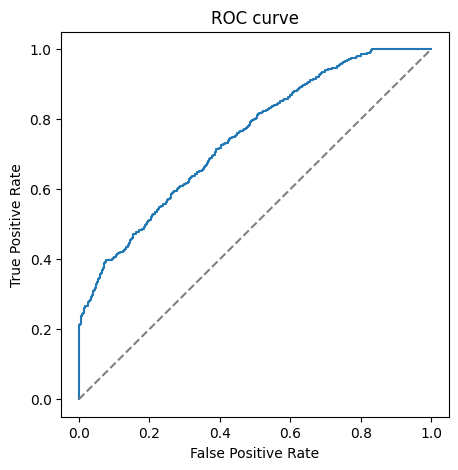

In [6]:
baseline_pipeline = Pipeline(steps=[
    ('baseline_error_deleter', SimpleErrorDeleter()),
    ('catboost', CatBoostClassifier(silent=True))
])

baseline_pipeline.fit(X_train, y_train)
y_test_pred_bl = baseline_pipeline.predict(X_test)
y_test_proba_bl = baseline_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_test, y_test_pred_bl, y_test_proba_bl)

## Логистическая регрессия

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as 

              precision    recall  f1-score   support

           0     0.8272    0.7220    0.7710      1313
           1     0.4993    0.6477    0.5639       562

    accuracy                         0.6997      1875
   macro avg     0.6633    0.6848    0.6675      1875
weighted avg     0.7289    0.6997    0.7090      1875

roc_auc_score = 0.7728287884906749


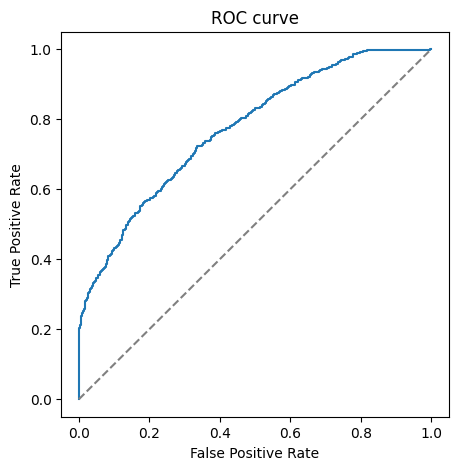

In [7]:
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler().set_output(transform='pandas')),
    ('LogisticRegression', LogisticRegression())
])
project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "LogisticRegression"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "LogisticRegression__C": optuna.distributions.FloatDistribution(0.001, 2000, log=True),
            "LogisticRegression__penalty": optuna.distributions.CategoricalDistribution(["l1", "l2"]),
            "LogisticRegression__class_weight": optuna.distributions.CategoricalDistribution([None, "balanced"]),
            "LogisticRegression__max_iter": optuna.distributions.IntDistribution(100, 1000)
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                log_reg_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("LogisticRegression__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "LogisticRegression",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

log_reg_pipeline.set_params(**{f"LogisticRegression__{k}": v for k, v in best_params_.items()})
log_reg_pipeline.fit(X_train, y_train)
y_train_pred_log_reg = log_reg_pipeline.predict(X_train)
y_train_proba_log_reg = log_reg_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_log_reg = log_reg_pipeline.predict(X_test)
y_test_proba_log_reg = log_reg_pipeline.predict_proba(X_test)[:, 1]
y_test_proba_0_log_reg = log_reg_pipeline.predict_proba(X_test)[:, 0]

#show_metrics(y_train, y_train_pred_log_reg, y_train_proba_log_reg)
show_metrics(y_test, y_test_pred_log_reg, y_test_proba_log_reg)

## Решающее дерево

              precision    recall  f1-score   support

           0     0.8137    0.6618    0.7299      1313
           1     0.4498    0.6459    0.5303       562

    accuracy                         0.6571      1875
   macro avg     0.6317    0.6539    0.6301      1875
weighted avg     0.7046    0.6571    0.6701      1875

roc_auc_score = 0.7382288529975363


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


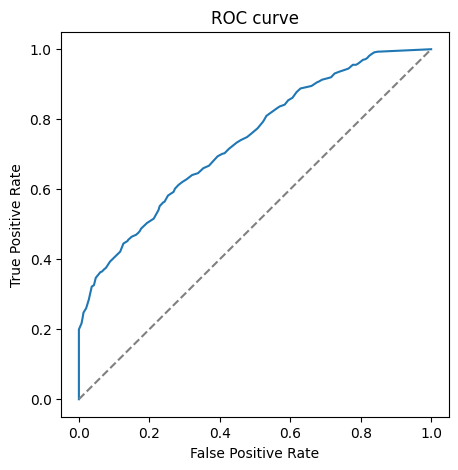

In [8]:
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('DecisionTree', DecisionTreeClassifier())
])

project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "DecisionTree"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "DecisionTree__max_depth": optuna.distributions.IntDistribution(1, 150),
            "DecisionTree__min_samples_split": optuna.distributions.IntDistribution(2, 100),
            "DecisionTree__min_samples_leaf": optuna.distributions.IntDistribution(1, 50),
            "DecisionTree__max_features": optuna.distributions.CategoricalDistribution([None, 'sqrt', 'log2']),
            "DecisionTree__random_state": optuna.distributions.IntDistribution(42, 42),
            "DecisionTree__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced', 'balanced_subsample'])      
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                dt_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("DecisionTree__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "DecisionTree",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

dt_pipeline.set_params(**{f"DecisionTree__{k}": v for k, v in best_params_.items()})
dt_pipeline.fit(X_train, y_train)
y_train_pred_dt = dt_pipeline.predict(X_train)
y_train_proba_dt = dt_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_dt = dt_pipeline.predict(X_test)
y_test_proba_dt = dt_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_dt, y_train_proba_dt)
show_metrics(y_test, y_test_pred_dt, y_test_proba_dt)

## Случайный лес

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.8264    0.6961    0.7557      1313
           1     0.4811    0.6584    0.5560       562

    accuracy                         0.6848      1875
   macro avg     0.6538    0.6772    0.6558      1875
weighted avg     0.7229    0.6848    0.6958      1875

roc_auc_score = 0.762278664220104


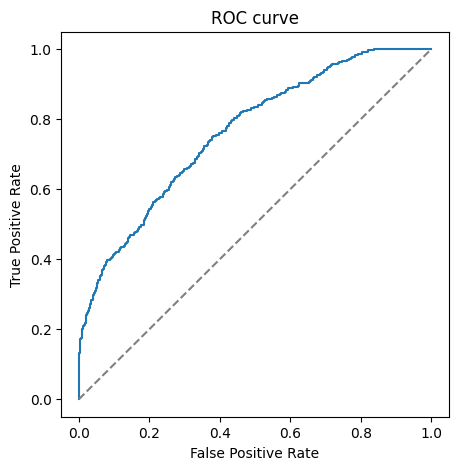

In [9]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "RandomForest"), None)
best_params_ = model_info["params"] if model_info else None
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('RandomForest', RandomForestClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "RandomForest__max_depth": optuna.distributions.IntDistribution(1, 30),
            "RandomForest__min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "RandomForest__min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "RandomForest__max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "RandomForest__n_estimators": optuna.distributions.IntDistribution(20, 500),
            "RandomForest__random_state": optuna.distributions.IntDistribution(42, 42),  
            "RandomForest__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced', 'balanced_subsample'])     
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                rf_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("RandomForest__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "RandomForest",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

rf_pipeline.set_params(**{f"RandomForest__{k}": v for k, v in best_params_.items()})
rf_pipeline.fit(X_train, y_train)
y_train_pred_rf = rf_pipeline.predict(X_train)
y_train_proba_rf = rf_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_rf = rf_pipeline.predict(X_test)
y_test_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_rf, y_train_proba_rf)
show_metrics(y_test, y_test_pred_rf, y_test_proba_rf)

## Градиентный бустинг

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.7733    0.9117    0.8368      1313
           1     0.6453    0.3754    0.4747       562

    accuracy                         0.7509      1875
   macro avg     0.7093    0.6435    0.6557      1875
weighted avg     0.7349    0.7509    0.7282      1875

roc_auc_score = 0.7417137142129213


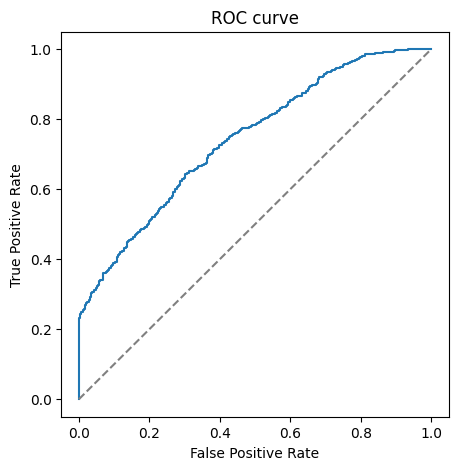

In [10]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('GradientBoosting', GradientBoostingClassifier())
])

model_info = next((p for p in configs if p["model_name"] == "GradientBoosting"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "GradientBoosting__max_depth": optuna.distributions.IntDistribution(1, 10),
            "GradientBoosting__min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "GradientBoosting__min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "GradientBoosting__max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "GradientBoosting__n_estimators": optuna.distributions.IntDistribution(20, 1500, log=True),
            "GradientBoosting__learning_rate": optuna.distributions.FloatDistribution(1e-5, 0.5, log=True),
            "GradientBoosting__random_state": optuna.distributions.IntDistribution(42, 42)     
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                gb_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("GradientBoosting__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "GradientBoosting",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

gb_pipeline.set_params(**{f"GradientBoosting__{k}": v for k, v in best_params_.items()})
gb_pipeline.fit(X_train, y_train)
y_train_pred_gb = gb_pipeline.predict(X_train)
y_train_proba_gb = gb_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_gb = gb_pipeline.predict(X_test)
y_test_proba_gb = gb_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_gb, y_train_proba_gb)
show_metrics(y_test, y_test_pred_gb, y_test_proba_gb)

## CatBoost

              precision    recall  f1-score   support

           0     0.8038    0.7426    0.7720      1313
           1     0.4894    0.5765    0.5294       562

    accuracy                         0.6928      1875
   macro avg     0.6466    0.6595    0.6507      1875
weighted avg     0.7096    0.6928    0.6993      1875

roc_auc_score = 0.7590302829899743


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


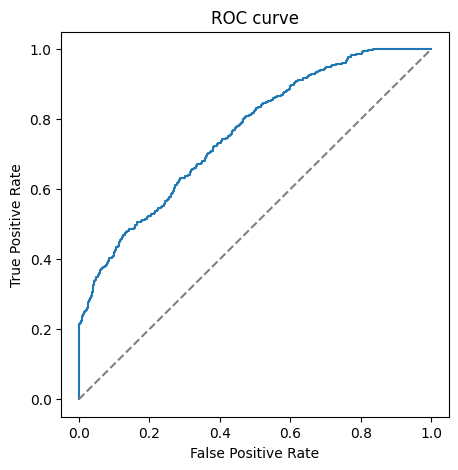

In [11]:
frozen_params = {
     'silent':True,
     'random_state':42
}
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "CatBoost"), None)
best_params_ = model_info["params"] if model_info else None
cb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('CatBoost', CatBoostClassifier(**frozen_params))
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "CatBoost__depth": optuna.distributions.IntDistribution(2, 10),
            "CatBoost__l2_leaf_reg": optuna.distributions.FloatDistribution(1e-2, 15, log=True),
            "CatBoost__iterations": optuna.distributions.IntDistribution(20, 1500, log=True),
            "CatBoost__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.5, log=True),
            "CatBoost__random_strength": optuna.distributions.FloatDistribution(1e-2, 1),
            "CatBoost__auto_class_weights": optuna.distributions.CategoricalDistribution(['None', 'Balanced', 'SqrtBalanced'])     
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                cb_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("CatBoost__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "CatBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

cb_pipeline.set_params(**{f"CatBoost__{k}": v for k, v in best_params_.items()})
cb_pipeline.fit(X_train, y_train)
y_train_pred_cb = cb_pipeline.predict(X_train)
y_train_proba_cb = cb_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_cb = cb_pipeline.predict(X_test)
y_test_proba_cb = cb_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_cb, y_train_proba_cb)
show_metrics(y_test, y_test_pred_cb, y_test_proba_cb)

## XGBoost

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.7742    0.9375    0.8481      1313
           1     0.7123    0.3612    0.4793       562

    accuracy                         0.7648      1875
   macro avg     0.7432    0.6494    0.6637      1875
weighted avg     0.7557    0.7648    0.7376      1875

roc_auc_score = 0.7605860367038619


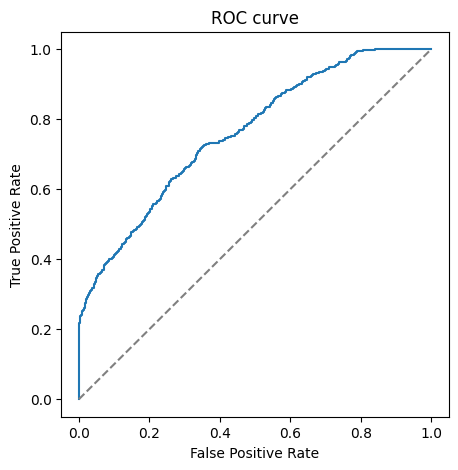

In [12]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "XGBoost"), None)
best_params_ = model_info["params"] if model_info else None
xg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('XGBoost', XGBClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "XGBoost__n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "XGBoost__max_depth": optuna.distributions.IntDistribution(2, 10),
            "XGBoost__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "XGBoost__reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10),
            "XGBoost__random_state": optuna.distributions.IntDistribution(42, 42)    
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                xg_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("XGBoost__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "XGBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

xg_pipeline.set_params(**{f"XGBoost__{k}": v for k, v in best_params_.items()})
xg_pipeline.fit(X_train, y_train)
y_train_pred_xg = xg_pipeline.predict(X_train)
y_train_proba_xg = xg_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_xg = xg_pipeline.predict(X_test)
y_test_proba_xg = xg_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_xg, y_train_proba_xg)
show_metrics(y_test, y_test_pred_xg, y_test_proba_xg)

## LightGBM

              precision    recall  f1-score   support

           0     0.8333    0.6855    0.7522      1313
           1     0.4805    0.6797    0.5630       562

    accuracy                         0.6837      1875
   macro avg     0.6569    0.6826    0.6576      1875
weighted avg     0.7276    0.6837    0.6955      1875

roc_auc_score = 0.7646868300298413


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


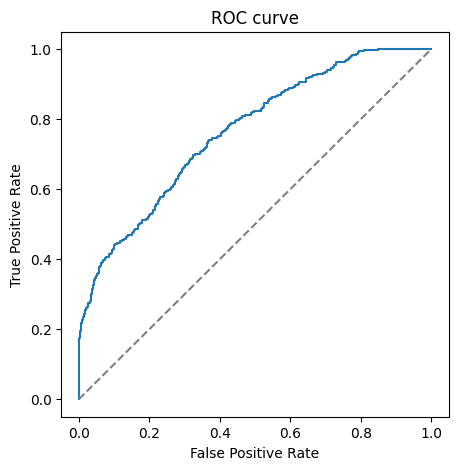

In [13]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "LightGBM"), None)
best_params_ = model_info["params"] if model_info else None
lgbm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('LightGBM', LGBMClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "LightGBM__n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "LightGBM__max_depth": optuna.distributions.IntDistribution(2, 15),
            "LightGBM__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "LightGBM__reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10),
            "LightGBM__num_leaves": optuna.distributions.IntDistribution(7, 255),
            "LightGBM__min_data_in_leaf": optuna.distributions.IntDistribution(20, 100),
            "LightGBM__subsample": optuna.distributions.FloatDistribution(0.8, 1),
            "LightGBM__feature_fraction": optuna.distributions.FloatDistribution(0.3, 1),
            "LightGBM__random_state": optuna.distributions.IntDistribution(42, 42),
            "LightGBM__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced']),
            "LightGBM__verbosity" : optuna.distributions.IntDistribution(-1, -1)
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                lgbm_pipeline,
                param_grid,
                cv=cv,
                n_trials=100,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("LightGBM__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "LightGBM",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

lgbm_pipeline.set_params(**{f"LightGBM__{k}": v for k, v in best_params_.items()})
lgbm_pipeline.fit(X_train, y_train)
y_train_pred_lgbm = lgbm_pipeline.predict(X_train)
y_train_proba_lgbm = lgbm_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_lgbm = lgbm_pipeline.predict(X_test)
y_test_proba_lgbm = lgbm_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_lgbm, y_train_proba_lgbm)
show_metrics(y_test, y_test_pred_lgbm, y_test_proba_lgbm)

## SVM

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


              precision    recall  f1-score   support

           0     0.8088    0.7411    0.7734      1313
           1     0.4940    0.5907    0.5381       562

    accuracy                         0.6960      1875
   macro avg     0.6514    0.6659    0.6558      1875
weighted avg     0.7145    0.6960    0.7029      1875

roc_auc_score = 0.7599260610430054


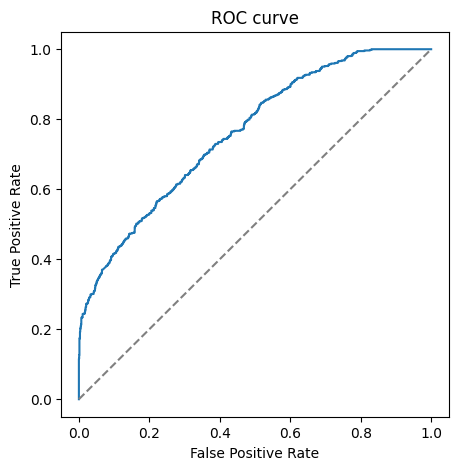

In [14]:
svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('SVM', SVC())
])

project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "SVM"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "SVM__C": optuna.distributions.FloatDistribution(1e-2, 300, log=True),
            "SVM__gamma": optuna.distributions.FloatDistribution(1e-5, 1, log=True),
            "SVM__kernel": optuna.distributions.CategoricalDistribution(['rbf']),
            "SVM__probability": optuna.distributions.CategoricalDistribution([True]),
            "SVM__class_weight": optuna.distributions.CategoricalDistribution(['balanced']),
            "SVM__random_state": optuna.distributions.IntDistribution(42, 42)      
        }

    cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                svm_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("SVM__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "SVM",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

svm_pipeline.set_params(**{f"SVM__{k}": v for k, v in best_params_.items()})
svm_pipeline.fit(X_train, y_train)
y_train_pred_svm = svm_pipeline.predict(X_train)
y_train_proba_svm = svm_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_svm = svm_pipeline.predict(X_test)
y_test_proba_svm = svm_pipeline.predict_proba(X_test)[:, 1]

#show_metrics(y_train, y_train_pred_svm, y_train_proba_svm)
show_metrics(y_test, y_test_pred_svm, y_test_proba_svm)

## Попробуем применить стэкинг моделей (lr + lgbm + rf в качестве метамодели)

In [15]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

In [ ]:
base_models = {
    'lr': log_reg_pipeline,
    'lgbm': lgbm_pipeline,
    #'xgb': xg_pipeline
    #'rf': rf_pipeline,
    #'cb': cb_pipeline,
    #'svc': svm_pipeline
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Z_fit = pd.DataFrame(index=X_fit.index)
Z_valid = pd.DataFrame(index=X_valid.index)
Z_test = pd.DataFrame(index=X_test.index)

for name, model in base_models.items():

    oof_proba = cross_val_predict(clone(model), X_fit, y_fit, cv=cv, method='predict_proba', n_jobs=1)[:, 1]

    Z_fit[name] = oof_proba

    fitted_model = clone(model).fit(X_fit, y_fit)

    Z_valid[name] = fitted_model.predict_proba(X_valid)[:, 1]
    Z_test[name] = fitted_model.predict_proba(X_test)[:, 1]


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [ ]:
meta_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=3, 
    min_samples_leaf=30, 
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

meta_model.fit(Z_fit, y_fit)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",30
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [ ]:
y_proba = meta_model.predict_proba(Z_valid)[:, 1]

results = []

for threshold in np.arange(0.10, 0.71, 0.01):
    y_pred = (y_proba >= threshold).astype(int)

    results.append({
        'threshold': threshold,
        'f1_0': f1_score(y_valid, y_pred, pos_label=0),
        'f1_1': f1_score(y_valid, y_pred, pos_label=1),
        'recall_0': recall_score(y_valid, y_pred, pos_label=0),
        'recall_1': recall_score(y_valid, y_pred, pos_label=1)
    })

threshold_results = pd.DataFrame(results)

valid_thresholds = threshold_results[
    threshold_results['f1_0'] >= 0.7710
]

valid_thresholds.sort_values('f1_1', ascending=False).head(10)

,threshold,f1_0,f1_1,recall_0,recall_1
40,0.50,0.794771,0.563889,0.737864,0.674419
41,0.51,0.819142,0.546022,0.799757,0.581395
42,0.52,0.823674,0.544586,0.810680,0.568106
43,0.53,0.829774,0.543372,0.825243,0.551495
46,0.56,0.846291,0.541593,0.865291,0.508306
45,0.55,0.841099,0.538194,0.854369,0.514950
47,0.57,0.855309,0.537313,0.889563,0.478405
44,0.54,0.835337,0.532423,0.843447,0.518272
48,0.58,0.857635,0.511811,0.906553,0.431894
49,0.59,0.860080,0.509018,0.913835,0.421927


              precision    recall  f1-score   support

           0     0.8304    0.7235    0.7733      1313
           1     0.5034    0.6548    0.5692       562

    accuracy                         0.7029      1875
   macro avg     0.6669    0.6892    0.6713      1875
weighted avg     0.7324    0.7029    0.7121      1875

roc_auc_score = 0.7739786639490667


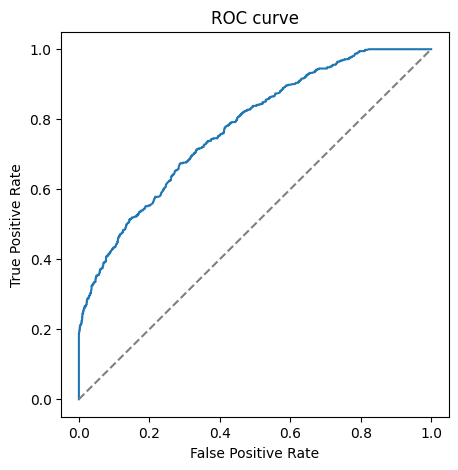

array([[950, 363],
       [194, 368]])

In [19]:
y_test_proba_stack = (meta_model.predict_proba(Z_test)[:, 1])
y_test_pred_stack = (y_test_proba_stack >= 0.5).astype(int)

show_metrics(y_test, y_test_pred_stack, y_test_proba_stack)
display(confusion_matrix(y_test, y_test_pred_stack))

# Проведем тест МакНемара для логистической регрессии и стека моделей

Сформулируем нулевую и альтернативную гипотезы:
1. `H0`: вероятность ошибок на тестовом наборе у сравниваемых моделей одинакова (ни одна из моделей систематически не показывает большей точности)
2. `H1`: вероятности ошибок различаются (одна модель работает лучше другой) 

Зададим уровень значимости `alpha = 0.05`. Если `p_value <= alpha`, то отклоняем `H0`, если `p_value > alpha`, то полученных данных не достаточно для отвержения `H0`

In [ ]:
temp = pd.DataFrame()
temp['y_true'] = y_test
temp['y_lr_pred'] = y_test_pred_log_reg
temp['y_stack_pred'] = y_test_pred_stack

correct_lr    = (temp['y_true'] == temp['y_lr_pred'])
correct_stack = (temp['y_true'] == temp['y_stack_pred'])

a = ( correct_lr &  correct_stack).sum()
b = ( correct_lr & ~correct_stack).sum()
c = (~correct_lr &  correct_stack).sum()
d = (~correct_lr & ~correct_stack).sum()

macnemar_array = [[a, b], [c, d]]

In [21]:
macnemar_array

[[np.int64(1224), np.int64(88)], [np.int64(94), np.int64(469)]]

In [22]:
result = mcnemar(macnemar_array, exact=False, correction=True)
print(f"Статистика: {result.statistic}, p-значение: {result.pvalue}")

Статистика: 0.13736263736263737, p-значение: 0.710917113388619


По результату теста МакНемара не удалось установить статистических различий между предсказаниями логистической регрессии и стека. Будем выбирать финальную модель, основываясь на метриках.

Используя стек, мы хоть и немного, но улучшаем всю совокупность метрик. Для финальных предсказаний будем использовать стек. Дополним `scr/transformers.py` трансформером, формирующим датафрейм для метамодели

In [23]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "MetaRandomForest"), None)
best_params_ = model_info["params"] if model_info else meta_model.get_params()
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('meta_transformer', MetaDataframeCreator(log_reg_pipeline.named_steps['LogisticRegression'], lgbm_pipeline.named_steps['LightGBM'])),
    ('final_estimator', RandomForestClassifier(**best_params_))
])


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


              precision    recall  f1-score   support

           0     0.8234    0.7494    0.7847      1313
           1     0.5162    0.6246    0.5652       562

    accuracy                         0.7120      1875
   macro avg     0.6698    0.6870    0.6750      1875
weighted avg     0.7313    0.7120    0.7189      1875

roc_auc_score = 0.7750817854848722


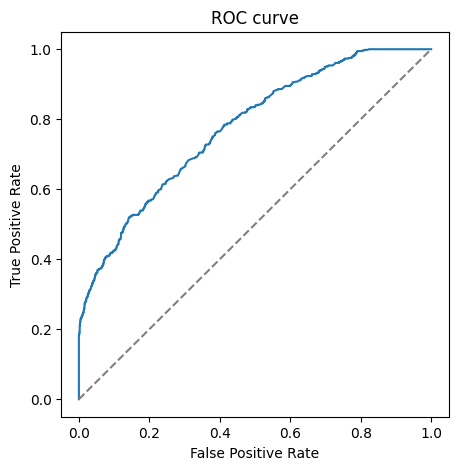

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
final_pipeline.fit(X_train, y_train)


y_final_pred = final_pipeline.predict(X_test)
y_final_proba = final_pipeline.predict_proba(X_test)[:, 1]
show_metrics(y_test, y_final_pred, y_final_proba)

Обучим пайплайн на всем датасете и сохраним 

In [25]:
output_path = project_root / 'models' / 'final_pipeline.joblib'
final_pipeline.fit(X, y)
joblib.dump(final_pipeline, output_path)

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


['d:\\credit_default\\models\\final_pipeline.joblib']